In [1]:
import torch
from PIL import Image
from transformers import AutoImageProcessor, AutoModelForDepthEstimation
import matplotlib.pyplot as plt
import numpy as np
import cv2

from transformers import AutoImageProcessor, AutoModelForDepthEstimation
from ipywidgets import interact, FloatSlider

`use_fast` is set to `True` but the image processor class does not have a fast version.  Falling back to the slow version.


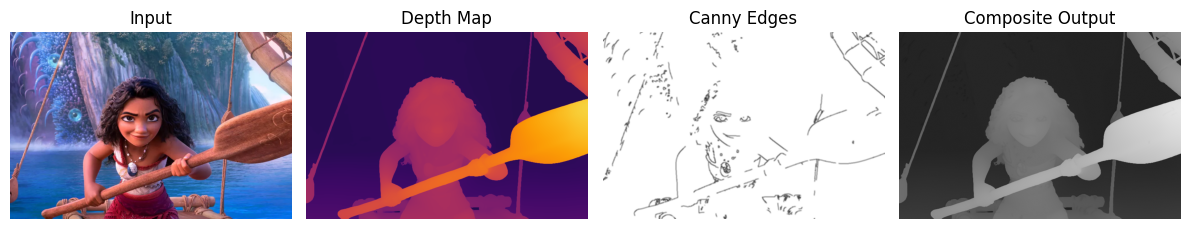

In [ ]:


# --- Hyperparameters ---
alpha_depth = 0.95   # Weight for normalized depth map
beta_gray = 0.0     # Weight for grayscale image
gamma_edges = 0.05   # Weight for edge map

# Step 1: Load the image
image_url = "imagenet/test/ILSVRC2010_test_00008937.JPEG"  # Replace with your own or a local file path
image_url = "0x0.webp"  # Replace with your own or a local file path
image = Image.open(image_url).convert("RGB")
image_np = np.array(image)

# Step 2: Load processor and model
model_name = "depth-anything/Depth-Anything-V2-Large-hf"  # Depth Anything V2 - small variant
processor = AutoImageProcessor.from_pretrained(model_name, use_fast=True)
model = AutoModelForDepthEstimation.from_pretrained(model_name)

# --- Preprocess ---
inputs = processor(images=image, return_tensors="pt")

# --- Predict Depth ---
with torch.no_grad():
    outputs = model(**inputs)
    predicted_depth = outputs.predicted_depth

# --- Resize Depth to Original Size ---
depth_resized = torch.nn.functional.interpolate(
    predicted_depth.unsqueeze(1),
    size=image.size[::-1],
    mode="bicubic",
    align_corners=False,
).squeeze()

depth_np = depth_resized.cpu().numpy()
depth_norm = (depth_np - depth_np.min()) / (depth_np.max() - depth_np.min())  # [0,1]

# --- Convert to Grayscale ---
gray = cv2.cvtColor(image_np, cv2.COLOR_RGB2GRAY)
gray_norm = gray.astype(np.float32) / 255.0  # [0,1]

# --- Canny Edge Detection ---

# --- Step 2: Canny edge detection ---
edges = cv2.Canny((gray_norm * 255).astype(np.uint8), 400, 200)

# --- Step 3: Blur edges for smooth blending ---
edges_blurred = cv2.GaussianBlur(edges.astype(np.float32), (5, 5), sigmaX=5.0)

# --- Step 4: Normalize for blending (invert to highlight edges as bright) ---
edges_norm = 1 - edges_blurred / 255.0  # [0,1]

# --- Blend Maps ---
# Stack into 3 channels for visualization (if needed)
depth_blend = depth_norm * alpha_depth
gray_blend = gray_norm * beta_gray
edges_blend = edges_norm * gamma_edges

# Final blended image
composite = np.clip(depth_blend + gray_blend + edges_blend, 0, 1)

# --- Display Results ---
plt.figure(figsize=(12, 6))

plt.subplot(1, 4, 1)
plt.imshow(image)
plt.title("Input")
plt.axis("off")

plt.subplot(1, 4, 2)
plt.imshow(depth_norm, cmap='inferno')
plt.title("Depth Map")
plt.axis("off")

plt.subplot(1, 4, 3)
plt.imshow(edges_norm, cmap='gray')
plt.title("Canny Edges")
plt.axis("off")

plt.subplot(1, 4, 4)
plt.imshow(composite, cmap='gray')
plt.title("Composite Output")
plt.axis("off")

plt.tight_layout()
plt.show()

In [2]:
import matplotlib.pyplot as plt
import numpy as np

# Assuming `composite` is a 2D NumPy array in [0, 1]
# Convert to 8-bit grayscale
composite_uint8 = (composite * 255).astype(np.uint8)

# Get image dimensions
h, w = composite_uint8.shape

# Determine size of the square crop (smallest dimension)
crop_size = min(h, w)

# Compute the top-left corner of the crop
start_y = (h - crop_size) // 2
start_x = (w - crop_size) // 2

# Perform central square crop
cropped_square = composite_uint8[start_y:start_y + crop_size, start_x:start_x + crop_size]

# Save the cropped image
plt.imsave("composite_output.jpg", cropped_square, cmap='gray', format='jpg')

In [45]:
cropped_square.shape

(224, 224)

In [2]:
import numpy as np
import scipy.sparse.linalg
import tqdm
import glob, pathlib

import working.diffmesh as dm
import working.helpers as H
import working.mesher as mesher
import torch

# ---------------------------

# args = parse_args()
# INFILE = "tmp/composite_output.png"
# OUTFILE = "rafael.png"
WIDTH = HEIGHT = 256
OFS = 0
GC_ALPHA = 10

# ---------------------------

# load depth image
def gen_hmap(in_file):
    hf = in_file
    # print(np.min(hf), np.max(hf))

    # we expect depth to increase with distance.  Flip it around.
    # hf = (255.0-hf)/255.0

    bkg_h = np.min( hf )

    ROWS, COLS = hf.shape

    # boundaries
    hf[0,:]=0.0
    hf[ROWS-1,:]=0.0
    hf[:,0]=0.0
    hf[:,COLS-1]=0.0

    def grad_compress( gx, gy, alpha=10.0 ):
        mags = np.sqrt( gx*gx + gy*gy + 0.0001 )
        cmags = (1.0/alpha) * np.log( 1.0 + alpha*mags )
        gx = gx / cmags
        gy = gy / cmags
        return gx, gy, cmags

    def rc_to_linind( r,c ):
        return r*COLS+c

    gx = np.zeros((ROWS,COLS),dtype=np.float32)
    gy = np.zeros((ROWS,COLS),dtype=np.float32)
    for row_ind in range(1,ROWS-1):
        for col_ind in range(1,COLS-1):
            gx[row_ind,col_ind] = hf[row_ind,col_ind+OFS]-hf[row_ind,col_ind-1]
            gy[row_ind,col_ind] = hf[row_ind+OFS,col_ind]-hf[row_ind-1,col_ind]        

    comp_gx, comp_gy, cmags = grad_compress( gx, gy, GC_ALPHA)

    row_inds = []
    col_inds = []
    data = []
    b = []
    next_ind = ROWS*COLS
    for row_ind in range(ROWS):
        for col_ind in range(COLS):
            xlc   = rc_to_linind( row_ind, col_ind )
            # boundary condition
            if row_ind == 0 or row_ind == ROWS-1 or col_ind == 0 or col_ind == COLS-1: # or hf[row_ind,col_ind] == bkg_h:
                row_inds.append(xlc); col_inds.append(xlc); data.append(1);
                b.append( 0 )
                continue
            
            # dx constraint
            xlc_l = rc_to_linind( row_ind, col_ind-1 )
            xlc_r = rc_to_linind( row_ind, col_ind+OFS )
            row_inds.append(xlc); col_inds.append(xlc_l); data.append(-1);
            row_inds.append(xlc); col_inds.append(xlc_r); data.append(1);
            # target value
            b.append( comp_gx[row_ind,col_ind] )

    next_ind = ROWS*COLS
    for row_ind in range(ROWS):
        for col_ind in range(COLS):
            xlc   = rc_to_linind( row_ind, col_ind )
            # boundary condition
            if row_ind == 0 or row_ind == ROWS-1 or col_ind == 0 or col_ind == COLS-1: # or hf[row_ind,col_ind] == bkg_h:
                # already got these above
                continue
            
            # dy constraint
            xlc_u = rc_to_linind( row_ind-1, col_ind )
            xlc_d = rc_to_linind( row_ind+OFS, col_ind )
            row_inds.append(next_ind); col_inds.append(xlc_u); data.append(-1);  
            row_inds.append(next_ind); col_inds.append(xlc_d); data.append(1);
            # target value
            b.append( comp_gy[row_ind,col_ind] )
            
            next_ind += 1

    A = scipy.sparse.csc_matrix( (data,(row_inds,col_inds)) )
    b = np.atleast_2d( b ).T

    results = scipy.sparse.linalg.lsqr( A, b, show=False, atol=1e-15, btol=1e-15, conlim=100 )

    new_hf = np.reshape( np.atleast_2d( results[0] ).T, (ROWS,COLS) )

    new_hf_img = new_hf - np.min(new_hf)
    new_hf_img = new_hf_img / np.max(new_hf_img)

    return new_hf_img

def eval_uv(tex, uvs):
    h, w = tex.shape
    _uvs = uvs.copy()
    uf, ui = np.modf(_uvs[:, 0] * w - 0.5)
    vf, vi = np.modf(_uvs[:, 1] * h - 0.5)
    uf[uf < 0] = 1 + uf[uf < 0]
    vf[vf < 0] = 1 + vf[vf < 0]
    ui = np.maximum(ui.astype(int), 0)
    vi = np.maximum(vi.astype(int), 0)
    vals = np.column_stack([tex[vi, ui], tex[vi, np.minimum(ui + 1, w - 1)], tex[np.minimum(vi + 1, h - 1), ui], tex[np.minimum(vi + 1, h - 1), np.minimum(ui + 1, w - 1)]])
    return (1 - vf) * (1 - uf) * vals[:, 0] + (1 - vf) * uf * vals[:, 1] + vf * (1 - uf) * vals[:, 2] + vf * uf * vals[:, 3]

def smoothness(tex_torch):
    data_padded = torch.nn.functional.pad(tex_torch, (1, 1, 1, 1), value=0)
    # minimize squared laplacian
    lap = data_padded[:-2, 1:-1] + data_padded[2:, 1:-1] + data_padded[1:-1, :-2] + data_padded[1:-1, 2:] - 4 * data_padded[1:-1, 1:-1]
    loss = torch.mean(lap * lap)
    return loss

def optimize_tex(tex, edge_border, iterations=100, smoothness_wt=0.1):
    tex_torch = torch.tensor(tex, device="cuda")
    orig = torch.nn.functional.pad(tex_torch.clone(), (edge_border, edge_border, edge_border, edge_border), value=0)
    tex_torch.requires_grad = True

    optimizer = torch.optim.Adam([tex_torch], lr=0.01)
    
    for _ in tqdm.trange(iterations):
        optimizer.zero_grad()
        hfield = torch.nn.functional.pad(tex_torch, (edge_border, edge_border, edge_border, edge_border), value=0)
        # apply smoothness loss
        sm = smoothness(hfield) * smoothness_wt
        tx = torch.mean((hfield - orig) ** 2)
        loss = sm + tx
        loss.backward()
        optimizer.step()
    
    optimized_tex = tex_torch.detach().cpu().numpy()
    return optimized_tex

def preprocess_tex(tex_torch, edge_border):
    hfield = np.pad(tex_torch, edge_border, mode="constant", constant_values=0)
    return hfield

def rect_points_to_uv(points, x_min=-0.3, x_max=0.3, z_min=-0.3, z_max=0.3, uvmin=0.0001, uvmax=0.9999):
    return np.column_stack([(points[:, 0] - x_min) / (x_max - x_min) * (uvmax - uvmin) + uvmin, (points[:, 2] - z_min) / (z_max - z_min) * (uvmax - uvmin) + uvmin])

def gen_relief(hmap, out_file, ht=0.05):
    Ps, Es = mesher.box_mesher(0.02, 0.6, 0.6, 0.15)

    # the points we want to optimize are those at the top of the box
    diff_pts_idx = np.where(np.isclose(Ps[:, 1], np.max(Ps[:, 1])))[0]
    diff_Ps = Ps[diff_pts_idx]

    # subdivide top faces if needed
    top_Es_idx = np.where(np.all(np.isin(Es, diff_pts_idx), axis=1))[0]
    Ps, Es = mesher.face_subdivision(Ps, Es, top_Es_idx, 1)
    # the points we want to optimize are those at the top of the box
    diff_pts_idx = np.where(np.isclose(Ps[:, 1], np.max(Ps[:, 1])))[0]
    diff_Ps = Ps[diff_pts_idx]

    x_max, y_max, z_max = np.max(Ps, axis=0)
    x_min, y_min, z_min = np.min(Ps, axis=0)
    diff_uvs = rect_points_to_uv(diff_Ps, x_min, x_max, z_min, z_max)

    # load image
    ht_low = -ht
    ht_high = ht
    tex = (hmap - np.min(hmap)) / (np.max(hmap) - np.min(hmap)) * (ht_high - ht_low) + ht_low
    # tex = optimize_tex(tex, edge_border=2, iterations=100, smoothness_wt=7)
    # tex = preprocess_tex(tex, edge_border=2)
    # save text to tmp
    # import matplotlib.pyplot as plt
    # plt.imsave(f"tmp/{pathlib.Path(out_file).stem}_gray.png", tex, cmap="gray")
    # diffmesh = dm.DiffMesh(Ps, Es)
    # CAM_POS = [(np.pi / 2, 0)] + [(np.pi / 4, i / 2 * np.pi) for i in range(4)]
    # rendered_imgs = [diffmesh.render(tex, *cam, radius=1) for cam in CAM_POS]
    # H.save_images(f"tmp/{pathlib.Path(out_file).stem}_renders.png", rendered_imgs + [tex], auto_grid=True)

    heights = eval_uv(tex, diff_uvs)
    Ps[diff_pts_idx, 1] -= heights
    H.save_mesh(out_file, Ps, Es)

In [3]:
import numpy as np
import cv2

def contrast(
    depth_np,
    method="clip",
    clip_percentiles=(5, 95),
    gamma=None,
    clahe_clip_limit=2.0,
    clahe_tile_grid=(8, 8)
):
    """
    Enhance contrast of a depth map.

    Parameters:
    - depth_np: 2D numpy array (raw depth map)
    - method: "clip", "equalize", or "clahe"
    - clip_percentiles: Tuple of (low, high) percentiles for 'clip' method
    - gamma: Apply optional gamma correction (e.g., 0.8 for boost)
    - clahe_clip_limit: CLAHE clip limit (if using 'clahe')
    - clahe_tile_grid: CLAHE tile grid size (if using 'clahe')

    Returns:
    - depth_contrast: 2D numpy array with values in [0, 1]
    """
    if method == "clip":
        vmin = np.percentile(depth_np, clip_percentiles[0])
        vmax = np.percentile(depth_np, clip_percentiles[1])
        depth = np.clip(depth_np, vmin, vmax)
        depth_contrast = (depth - vmin) / (vmax - vmin)

    elif method == "equalize":
        depth_uint8 = (depth_np - depth_np.min()) / (depth_np.max() - depth_np.min())
        depth_uint8 = (depth_uint8 * 255).astype(np.uint8)
        equalized = cv2.equalizeHist(depth_uint8)
        depth_contrast = equalized.astype(np.float32) / 255.0

    elif method == "clahe":
        depth_uint8 = (depth_np - depth_np.min()) / (depth_np.max() - depth_np.min())
        depth_uint8 = (depth_uint8 * 255).astype(np.uint8)
        clahe = cv2.createCLAHE(clipLimit=clahe_clip_limit, tileGridSize=clahe_tile_grid)
        clahe_result = clahe.apply(depth_uint8)
        depth_contrast = clahe_result.astype(np.float32) / 255.0

    else:
        raise ValueError("Unsupported method. Use 'clip', 'equalize', or 'clahe'.")

    # Optional gamma correction
    if gamma is not None:
        depth_contrast = np.power(depth_contrast, gamma)

    return depth_contrast

In [4]:
# --- Load Image ---
image_path = "imagenet/test/ILSVRC2010_test_00000015.JPEG"  # Replace with your image file path
image_path = "flowers.png"  # Replace with your image file path
image = Image.open(image_path).convert("RGB")
image_np = np.array(image)

# --- Load model ---
model_name = "depth-anything/Depth-Anything-V2-Large-hf"
processor = AutoImageProcessor.from_pretrained(model_name, use_fast=True)
model = AutoModelForDepthEstimation.from_pretrained(model_name)

# --- Predict Depth ---
inputs = processor(images=image, return_tensors="pt")
with torch.no_grad():
    outputs = model(**inputs)
    predicted_depth = outputs.predicted_depth

# --- Resize to original image size ---
depth_resized = torch.nn.functional.interpolate(
    predicted_depth.unsqueeze(1),
    size=image.size[::-1],
    mode="bicubic",
    align_corners=False,
).squeeze()

depth_np = depth_resized.cpu().numpy()
depth_norm = ((depth_np - depth_np.min()) / (depth_np.max() - depth_np.min()))


`use_fast` is set to `True` but the image processor class does not have a fast version.  Falling back to the slow version.


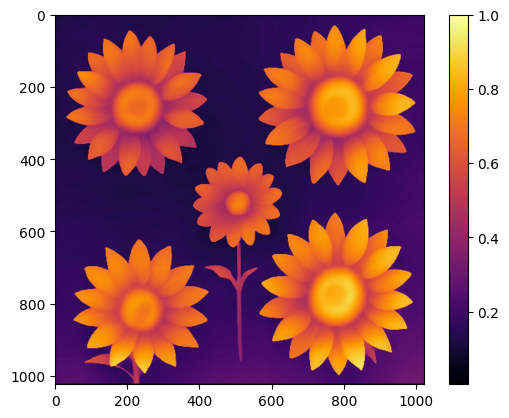

In [16]:
plt.imshow(contrast(depth_norm, method='clahe'), cmap='inferno')
plt.colorbar()
plt.show()

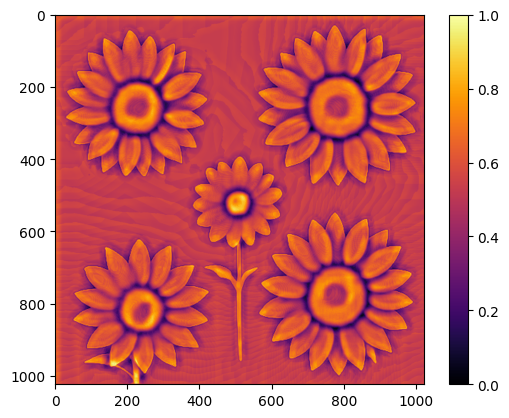

In [14]:
hmap = gen_hmap(contrast(depth_norm, method='clahe'))
plt.imshow(hmap, cmap='inferno')
plt.colorbar()
plt.show()

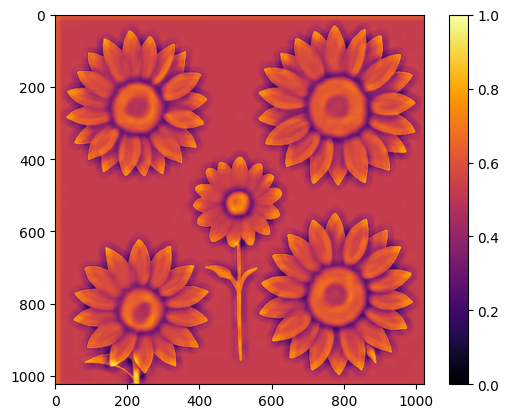

In [15]:
hmap = gen_hmap(depth_norm)
plt.imshow(hmap, cmap='inferno')
plt.colorbar()
plt.show()

In [119]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

# Assume hmap is already created from gen_hmap(depth_norm)

def center_crop_to_square(img):
    h, w = img.shape[:2]
    min_dim = min(h, w)
    top = (h - min_dim) // 2
    left = (w - min_dim) // 2
    return img[top:top+min_dim, left:left+min_dim]

def resize_image(img, size):
    return cv2.resize(img, (size, size), interpolation=cv2.INTER_AREA)

In [96]:
image_gray = image_np.mean(axis=-1)
image_norm = (image_gray - image_gray.min()) / (image_gray.max() - image_gray.min())

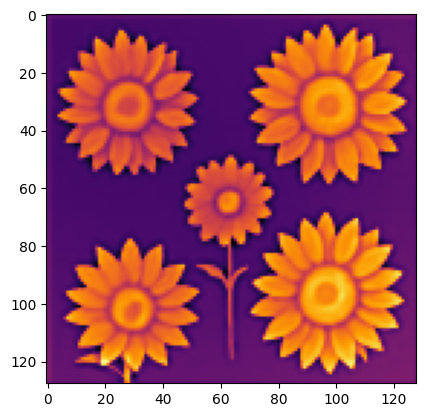

In [129]:
hmap_norm = (hmap - hmap.min()) / (hmap.max() - hmap.min())
hmap_square = center_crop_to_square((hmap_norm + depth_norm) / 2)
target_size = 128  # Example size
hmap_resized = resize_image(hmap_square, target_size)
hmap_resized = (hmap_resized - hmap_resized.min()) / (hmap_resized.max() - hmap_resized.min())

# Normalize hmap
plt.imshow(hmap_resized, cmap='inferno')

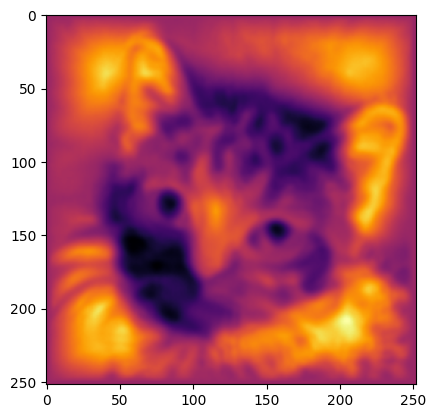

In [124]:
cat = np.load('cat.npy')
plt.imshow(cat, cmap='inferno')

In [ ]:
gen_relief(1 - hmap_resized, f"working/reliefs/test.obj", ht=0.05)